# Herramientas · Interfaces, juegos y *dashboards*

Aplicaciones con ventana (`PyQt6`), juegos (`pygame`) y paneles web (`streamlit`). Cada programa se guarda como script para ejecutarlo desde la terminal; en el notebook se prueba su lógica sin abrir ventanas.

## 1. Contador con PyQt distribuible

La aplicación tiene un contador y un botón que lo incrementa (al llegar a 100 muestra 🎉). Probarla sin pantalla (plataforma `offscreen`) y empaquetarla con `pyinstaller` para usuarios sin Python (`--windowed` evita la consola). Para verla: `python contador_pyqt.py`.

In [1]:
import os
import subprocess
import sys

codigo = '''import sys
from PyQt6.QtWidgets import QApplication, QHBoxLayout, QLabel, QPushButton, QWidget

class AppContador(QWidget):
    def __init__(self):
        super().__init__()
        self.contador = 0
        self.setWindowTitle("Contador")
        self.setGeometry(100, 100, 300, 200)
        layout = QHBoxLayout()
        self.label = QLabel("0", self)
        self.label.setStyleSheet("font-size: 30px;")
        self.button = QPushButton("Incrementar", self)
        self.button.clicked.connect(self.suma_contador)
        layout.addWidget(self.label)
        layout.addWidget(self.button)
        self.setLayout(layout)

    def suma_contador(self):
        self.contador += 1
        if self.contador == 100:
            self.label.setText("🎉")
            self.contador = 0
        else:
            self.label.setText(str(self.contador))

if __name__ == "__main__":
    app = QApplication(sys.argv)
    w = AppContador()
    w.show()
    sys.exit(app.exec())
'''
with open("contador_pyqt.py", "w", encoding="utf-8") as f:
    f.write(codigo)

prueba = '''from PyQt6.QtWidgets import QApplication
from contador_pyqt import AppContador
app = QApplication([])
w = AppContador()
for _ in range(5):
    w.button.click()
print(w.label.text(), end=" ")
for _ in range(95):
    w.button.click()
print(w.label.text())
'''
entorno = {**os.environ, "QT_QPA_PLATFORM": "offscreen", "PYTHONIOENCODING": "utf-8"}
print(subprocess.run([sys.executable, "-c", prueba], env=entorno, capture_output=True, text=True, encoding="utf-8").stdout)

subprocess.run([sys.executable, "-m", "PyInstaller", "--onefile", "--windowed", "--clean", "--noconfirm", "--log-level", "ERROR",
                "--distpath", "dist", "--workpath", "build", "contador_pyqt.py"], check=True)
print(sorted(os.listdir("dist")))

5 🎉

['contador_pyqt.exe']


## 2. Juego con límites y *Snake* en `pygame`

En el juego base se mueve un rectángulo con las flechas. Evitar que el jugador salga de la pantalla e implementar el juego *Snake*: la serpiente crece al comer y se pierde al chocar con los bordes o consigo misma. Para jugar: `python snake.py`. Aquí se prueba con un piloto automático sin ventana (`SDL_VIDEODRIVER=dummy`) y se guarda una captura.

rectángulo dentro: (380, 0)
longitud y pasos: (24, 300)



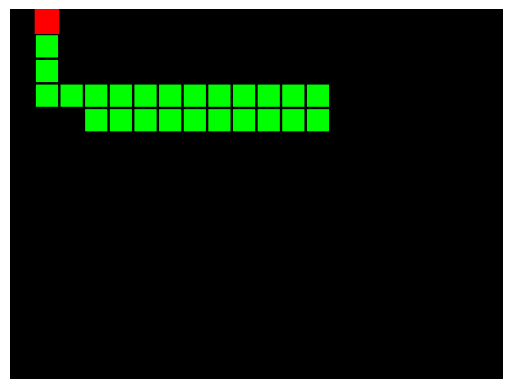

In [2]:
codigo = r'''import random
import sys
import pygame

ANCHO, ALTO, CELDA = 400, 300, 20
COLUMNAS, FILAS = ANCHO // CELDA, ALTO // CELDA

def limita(rect):
    # rectángulo base: clamp_ip lo mantiene dentro de la pantalla
    rect.clamp_ip(pygame.Rect(0, 0, ANCHO, ALTO))

def nueva_comida(serpiente):
    libres = [(x, y) for x in range(COLUMNAS) for y in range(FILAS) if (x, y) not in serpiente]
    return random.choice(libres)

def paso(serpiente, direccion, comida):
    cabeza = (serpiente[0][0] + direccion[0], serpiente[0][1] + direccion[1])
    if not (0 <= cabeza[0] < COLUMNAS and 0 <= cabeza[1] < FILAS) or cabeza in serpiente[:-1]:
        return serpiente, comida, False
    serpiente = [cabeza] + serpiente
    if cabeza == comida:
        comida = nueva_comida(serpiente)
    else:
        serpiente.pop()
    return serpiente, comida, True

def piloto(serpiente, direccion, comida):
    opciones = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    seguras = []
    for d in opciones:
        c = (serpiente[0][0] + d[0], serpiente[0][1] + d[1])
        if 0 <= c[0] < COLUMNAS and 0 <= c[1] < FILAS and c not in serpiente[:-1]:
            seguras.append((abs(c[0] - comida[0]) + abs(c[1] - comida[1]), d))
    return min(seguras)[1] if seguras else direccion

def dibuja(pantalla, serpiente, comida):
    pantalla.fill((0, 0, 0))
    pygame.draw.rect(pantalla, (255, 0, 0), (comida[0] * CELDA, comida[1] * CELDA, CELDA, CELDA))
    for x, y in serpiente:
        pygame.draw.rect(pantalla, (0, 255, 0), (x * CELDA + 1, y * CELDA + 1, CELDA - 2, CELDA - 2))

def main(demo_pasos=None, captura=None):
    random.seed(1)
    pygame.init()
    pantalla = pygame.display.set_mode((ANCHO, ALTO))
    serpiente, direccion = [(5, 5), (4, 5), (3, 5)], (1, 0)
    comida = nueva_comida(serpiente)
    teclas = {pygame.K_LEFT: (-1, 0), pygame.K_RIGHT: (1, 0), pygame.K_UP: (0, -1), pygame.K_DOWN: (0, 1)}
    reloj, vivo, pasos = pygame.time.Clock(), True, 0
    while vivo and (demo_pasos is None or pasos < demo_pasos):
        for evento in pygame.event.get():
            if evento.type == pygame.QUIT:
                vivo = False
            elif evento.type == pygame.KEYDOWN and evento.key in teclas:
                nueva = teclas[evento.key]
                if (nueva[0] + direccion[0], nueva[1] + direccion[1]) != (0, 0):
                    direccion = nueva
        if demo_pasos is not None:
            direccion = piloto(serpiente, direccion, comida)
        serpiente, comida, vivo = paso(serpiente, direccion, comida)
        dibuja(pantalla, serpiente, comida)
        pygame.display.flip()
        pasos += 1
        if demo_pasos is None:
            reloj.tick(10)
    if captura:
        pygame.image.save(pantalla, captura)
    pygame.quit()
    return len(serpiente), pasos

if __name__ == "__main__":
    if len(sys.argv) > 1:
        print(main(int(sys.argv[1]), sys.argv[2]))
    else:
        main()
'''
with open("snake.py", "w", encoding="utf-8") as f:
    f.write(codigo)

prueba = '''import pygame, snake
pygame.init()
r = pygame.Rect(390, -15, 20, 20)
snake.limita(r)
print("rectángulo dentro:", r.topleft)
print("longitud y pasos:", snake.main(300, "snake.png"))
'''
entorno = {**os.environ, "SDL_VIDEODRIVER": "dummy", "PYGAME_HIDE_SUPPORT_PROMPT": "1"}
print(subprocess.run([sys.executable, "-c", prueba], env=entorno, capture_output=True, text=True).stdout)

import matplotlib.pyplot as plt
plt.imshow(plt.imread("snake.png"))
plt.axis("off")
plt.show()

## 3. *Dashboard* de esperanza de vida con `streamlit`

El panel permite seleccionar países y comparar su esperanza de vida. Añadir el histograma de la esperanza de vida de todos los países y su evolución a lo largo de los años con un deslizador de año. Para verlo: `streamlit run dashboard_streamlit.py`; aquí se prueba con `AppTest`, que ejecuta la aplicación sin servidor.

In [3]:
codigo = '''import matplotlib.pyplot as plt
import pandas as pd
import streamlit as st

URL = "https://raw.githubusercontent.com/ellibrodepython/50-ejemplos-python/main/ejemplos/49_dashboard_streamlit.csv"

@st.cache_data
def carga():
    df = pd.read_csv(URL, skiprows=4)
    años = [c for c in df.columns if c.isdigit() and df[c].notna().any()]
    return df.set_index("Country Name")[años]

df = carga()
st.title("🌎 Esperanza de Vida Mundial")
paises = st.multiselect("✅ Selecciona países", df.index)
st.line_chart(df.loc[paises].T)

año = st.slider("Año", int(df.columns[0]), int(df.columns[-1]), int(df.columns[-1]))
fig, ax = plt.subplots()
ax.hist(df[str(año)].dropna(), bins=20, edgecolor="black")
ax.set(xlabel="Esperanza de vida (años)", ylabel="Países", title=f"Esperanza de vida en {año}")
st.pyplot(fig)
st.line_chart(df.describe().T[["25%", "50%", "75%"]])
'''
with open("dashboard_streamlit.py", "w", encoding="utf-8") as f:
    f.write(codigo)

from streamlit.testing.v1 import AppTest

at = AppTest.from_file("dashboard_streamlit.py", default_timeout=60).run()
at.multiselect[0].select("Spain").select("Japan").run()
at.slider[0].set_value(1990).run()
print(at.title[0].value, at.multiselect[0].value, at.slider[0].value, len(at.exception))

🌎 Esperanza de Vida Mundial ['Spain', 'Japan'] 1990 0
